# GEOL 415 Lab 8 -- XGBoost

Welcome to lab 8. Today we'll do more tree-based learning, this time with eXtreme Gradient Boosted (XGBoost) decision trees.

Learning Objectives:
- Load and process weather and climate data over Los Angeles County from 2014-2018 from the ERA5 reanalysis dataset.
- Train an XGBoost model to predict the temperature at a point near USC using other covariates.
- Split data into train and test sets by year, and describe at a high level how gradient boosting works.
- Evaluate an XGBoost regression model with error plots and common metrics (RMSE, MAE, $R^2$), and interpret feature importance.

## 0: Startup

Load up the packages we'll need for today's lab. If you have not done so, you'll need to install the `xgboost` library in your `geol415` environment. I'll provide that in a separate cell. **You do not need to install `xgboost` if you've already done so.**

In [1]:
# the classic environment check
import sys
print(sys.executable)

import numpy as np
import pandas as pd
# import netCDF4 as nc4 # pip install this if not already done
#%conda install -n geol415 -c conda-forge netcdf4
import xarray as xr
import matplotlib.pyplot as plt

/opt/anaconda3/envs/geol415/bin/python


In [2]:
# do not need to run if already installed
#%conda install -c conda-forge xgboost

# 1: Load and inspect data

Let's load up the ERA5 dataset and see what covariates we will be working with. This is a .nc file, which exists in a different format from the typical `pd.DataFrame`s I've been throwing at you. It's important to be comfortable working with data in nc format, as climate/environmental data (particularly spatial) is often stored in such structures.

Below shows you how you can open a .nc file using `xarray`

In [3]:
data = xr.open_dataset('la_era.nc')
data # shows us nicely what we're working with

<xarray.Dataset> Size: 259kB
Dimensions:     (time: 7200)
Coordinates:
  * time        (time) datetime64[ns] 58kB 2014-01-01 ... 2018-12-28T23:00:00
    valid_time  (time) datetime64[ns] 58kB ...
    number      int64 8B ...
    step        timedelta64[ns] 8B ...
    surface     float64 8B ...
    latitude    float64 8B ...
    longitude   float64 8B ...
Data variables:
    u10         (time) float32 29kB ...
    v10         (time) float32 29kB ...
    t2m         (time) float32 29kB ...
    sp          (time) float32 29kB ...
    tcc         (time) float32 29kB ...
Attributes:
    GRIB_edition:            1
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2026-10-21T20:41 GRIB to CDM+CF via cfgrib-0.9.1...

Here we have a dataset spanning the years 2014-2019 covering climate/weather variables at a single lat/lon pair. The variables we have are
- `u10`: the zonal (east-west) component of wind speed at 10m height above surface. **Units [=] meters/second**
- `v10`: the meridional (north-south) component of wind speed at 10m height above the surface. **Units [=] meters/second**
- `sp`: surface pressure. **Units [=] Pascals**
- `tcc`: total cloud cover at the specified grid point. **Units [=] scalar between [0,1].**
- `t2m`: the Temperature 2m above the surface. **Units [=] Kelvin.**

Today, you will use these variables to predict `t2m` using an XGBoost model

# Plot temperature time series

For xarray/netCdf files, you can access different data in the same way you would if this were a `pd.DataFrame`

#### **Question:** plot the time series of temperature near USC for the entire time span of our dataset.
Hint: you can plot nc data by column like in pandas, or you can specify further that you just want the `values` of the data array. Both will work below, but IMO it's best practice to get the values. I'll show you below for grabbing the time axis.

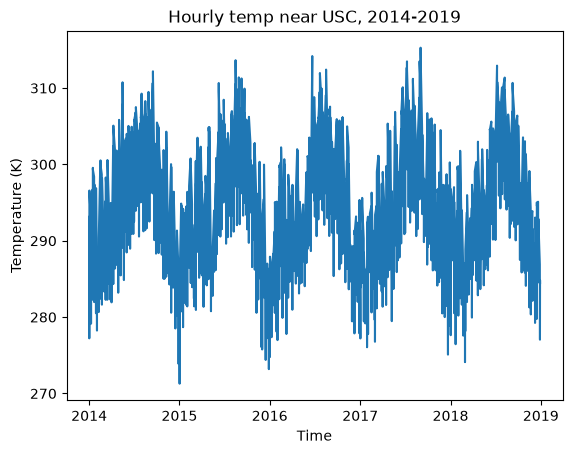

In [6]:
date = data['time'].values
temp = data['t2m'].values


plt.plot(date, temp)
plt.xlabel('Time')
plt.ylabel('Temperature (K)')
plt.title('Hourly temp near USC, 2014-2019');

#### **Question**: Convert the ncdata file to a pd dataframe using xarray's `to_dataframe()` method. 


In [7]:
df = data.to_dataframe().reset_index()
df

,time,u10,v10,t2m,sp,tcc,number,step,surface,latitude,longitude,valid_time
0,2014-01-01 00:00:00,1.026184,0.819427,293.122437,96097.6875,0.001892,0,0 days,0.0,34.0,-117.5,2014-01-01 00:00:00
1,2014-01-01 01:00:00,1.456955,0.808792,290.507080,96095.2500,0.128510,0,0 days,0.0,34.0,-117.5,2014-01-01 01:00:00
2,2014-01-01 02:00:00,0.923187,0.116745,288.278931,96127.8750,0.221222,0,0 days,0.0,34.0,-117.5,2014-01-01 02:00:00
3,2014-01-01 03:00:00,0.613968,-0.121475,285.289185,96125.8750,0.115051,0,0 days,0.0,34.0,-117.5,2014-01-01 03:00:00
4,2014-01-01 04:00:00,0.257294,0.017273,283.482178,96187.5625,0.005188,0,0 days,0.0,34.0,-117.5,2014-01-01 04:00:00
...,...,...,...,...,...,...,...,...,...,...,...,...
7195,2018-12-28 19:00:00,-1.983398,-4.320358,283.494385,96055.0000,0.000000,0,0 days,0.0,34.0,-117.5,2018-12-28 19:00:00
7196,2018-12-28 20:00:00,-2.090088,-4.216873,284.109131,95971.6250,0.000000,0,0 days,0.0,34.0,-117.5,2018-12-28 20:00:00
7197,2018-12-28 21:00:00,-1.909317,-3.983719,284.835693,95969.6250,0.000000,0,0 days,0.0,34.0,-117.5,2018-12-28 21:00:00
7198,2018-12-28 22:00:00,-1.713959,-2.841446,284.643066,95977.1875,0.000000,0,0 days,0.0,34.0,-117.5,2018-12-28 22:00:00


#### Also, drop the `surface`, `latitude`, `valid_time`, `number`, `step`, and `longitude` columns.
These are just clutter for our purposes.

In [8]:
df = df.drop(columns=['surface','latitude','valid_time','number','step','longitude'], errors="ignore")
df

,time,u10,v10,t2m,sp,tcc
0,2014-01-01 00:00:00,1.026184,0.819427,293.122437,96097.6875,0.001892
1,2014-01-01 01:00:00,1.456955,0.808792,290.507080,96095.2500,0.128510
2,2014-01-01 02:00:00,0.923187,0.116745,288.278931,96127.8750,0.221222
3,2014-01-01 03:00:00,0.613968,-0.121475,285.289185,96125.8750,0.115051
4,2014-01-01 04:00:00,0.257294,0.017273,283.482178,96187.5625,0.005188
...,...,...,...,...,...,...
7195,2018-12-28 19:00:00,-1.983398,-4.320358,283.494385,96055.0000,0.000000
7196,2018-12-28 20:00:00,-2.090088,-4.216873,284.109131,95971.6250,0.000000
7197,2018-12-28 21:00:00,-1.909317,-3.983719,284.835693,95969.6250,0.000000
7198,2018-12-28 22:00:00,-1.713959,-2.841446,284.643066,95977.1875,0.000000


# 2: Prepare features and target

You may have noticed the very large temp values in your plot above. ERA5 temperature data are recorded in units of **Kelvin**. Kelvin and Celsius are related by the following relation:

$$K = C + 273.15$$

Let's convert temperature to Celsius, which is easier to interpret. We'll also convert surface pressure from Pa to hPa.

#### Question: Create a new column `t2m_C` that holds the temperature in degrees Celsius, and a column `sp_hPa` that holds surface pressure in hectopascals (HINT: 1 hPa = 100 Pa).

In [9]:
df['t2m_C'] = df['t2m'] - 273.15
df['sp_hPa'] = df['sp'] / 100
df[['t2m', 't2m_C', 'sp', 'sp_hPa']].head()

,t2m,t2m_C,sp,sp_hPa
0,293.122437,19.972443,96097.6875,960.976868
1,290.507080,17.357086,96095.2500,960.952515
2,288.278931,15.128937,96127.8750,961.278748
3,285.289185,12.139191,96125.8750,961.258728
4,283.482178,10.332184,96187.5625,961.875610


We'll also pull out the year from `time`. This is **not** a feature; we only need it to split the data in the next section.

In [10]:
df['year'] = df['time'].dt.year

features = ['u10', 'v10', 'sp_hPa', 'tcc']
target = 't2m_C'

df[['time', 'year'] + features + [target]].head()

,time,year,u10,v10,sp_hPa,tcc,t2m_C
0,2014-01-01 00:00:00,2014,1.026184,0.819427,960.976868,0.001892,19.972443
1,2014-01-01 01:00:00,2014,1.456955,0.808792,960.952515,0.128510,17.357086
2,2014-01-01 02:00:00,2014,0.923187,0.116745,961.278748,0.221222,15.128937
3,2014-01-01 03:00:00,2014,0.613968,-0.121475,961.258728,0.115051,12.139191
4,2014-01-01 04:00:00,2014,0.257294,0.017273,961.875610,0.005188,10.332184


> **Note on the data:** the file does not contain a continuous hourly record. It has 5 *non-consecutive* days of full hourly data per month (spread across days 1-28), for each of the 5 years, totaling 7,200 rows. That's fine for our purposes, but keep it in mind when you look at time series plots later: you will see gaps between the sampled days.

# 3: Train/test split

To judge how well a model generalizes, we must evaluate it on data it never saw during training. We'll split by **year**:

- **Train:** 2014-2017
- **Test:** 2018

We then **shuffle** the rows of each set. Tree models don't care about row order when fitting, but shuffling removes any ordering artifacts (e.g. all of January first) and is good practice, especially because XGBoost can subsample rows at each boosting round.

Splitting by year (instead of randomly across all rows) matters for weather data. Hourly weather is highly autocorrelated: the temperature at 2 pm is nearly identical to the temperature at 3 pm. A purely random split would put 2 pm in train and 3 pm in test, so the test set would not be independent of the training set and our score would be overly optimistic. Holding out an entire year gives a more honest estimate of performance on new data.

#### Question: Select the training rows (years 2014-2017) and test rows (year 2018), then shuffle each. Print the shapes.

In [11]:
train = df[(df['year'] >= 2014) & (df['year'] <= 2017)]
test  = df[df['year'] == 2018]

# shuffle rows (random_state makes this reproducible)
train = train.sample(frac=1, random_state=42)
test  = test.sample(frac=1, random_state=42)

X_train, y_train = train[features], train[target]
X_test,  y_test  = test[features],  test[target]

print('train:', X_train.shape, ' test:', X_test.shape)
print('train years:', sorted(int(y) for y in train['year'].unique()), ' test years:', sorted(int(y) for y in test['year'].unique()))

train: (5760, 4)  test: (1440, 4)
train years: [2014, 2015, 2016, 2017]  test years: [2018]


**Question:** Roughly what fraction of the data is in the training set? Why might using a whole year as the test set be a *harder* test than a random 80/20 split? *(Answer in 2-3 sentences.)*

> *About 80% of data is in the training set.  More data means more variation so testing on a larger data set would probably lead to our model seeming less accurate.*

# 4: What is XGBoost? A short primer

**XGBoost** (eXtreme Gradient Boosting) builds a prediction by adding together many small decision trees, one at a time. It is a *boosting* method, which is different from the random forest you saw last week, where we trained many trees independently and averaged their results.

**The idea:**

1. Start with a very simple prediction, such as the average temperature of the training set.
2. Look at the errors (residuals) the current model makes.
3. Train a small, shallow tree whose job is to predict those errors.
4. Add that tree's output to the model, scaled down by a **learning rate** $\eta$.
5. Repeat. Each new tree focuses on whatever the earlier trees still got wrong.

After $m$ trees, the prediction is

$$\hat{y}^{(m)} = \hat{y}^{(m-1)} + \eta \, f_m(x)$$

where $f_m$ is the newest tree.

**Why "gradient"?** This is **gradient descent**, but instead of nudging numeric parameters downhill on a loss function, each step adds a tree that points downhill on the loss. For squared-error loss, the downhill direction (the negative gradient) is exactly the residual, which is why fitting trees to residuals works. The learning rate plays the same role as the step size in ordinary gradient descent: a small $\eta$ takes cautious steps and needs more trees, while a large $\eta$ learns quickly but is more likely to overfit.

**Why "extreme"?** XGBoost adds regularization to discourage overly complex trees, uses second-derivative information for better steps, can subsample rows and columns for each tree, and is heavily optimized for speed.

**The main knobs (hyperparameters) we will use:**

| hyperparameter | what it controls |
|---|---|
| `n_estimators` | number of trees (boosting rounds) |
| `learning_rate` | how much each tree contributes ($\eta$) |
| `max_depth` | how deep, or how many "branches", each tree can grow (complexity of each weak learner) |
| `subsample` | fraction of training rows randomly used for each tree |

# 5: Train and test the XGBoost model

Because XGBoost is built from decision trees, which only ask questions like "is surface pressure < 955?", **we do not need to normalize or standardize the input features**, even though they are on very different scales (pressure is ~950, cloud cover is 0-1).

We'll pass both the train and test sets in `eval_set` so XGBoost records the loss on each after every round. That lets us watch the gradient descent happen.

In [13]:
import xgboost as xgb

model = xgb.XGBRegressor(
    n_estimators=70,
    learning_rate=0.2,
    max_depth=5,
    subsample=0.8,
    random_state=42,
    eval_metric='rmse',
)

model.fit(
    X_train, y_train,
    eval_set=[(X_train, y_train), (X_test, y_test)],
    verbose=True,
)

y_pred_train = model.predict(X_train)
y_pred_test  = model.predict(X_test)
print('Model trained!')

[0]	validation_0-rmse:7.04606	validation_1-rmse:6.95119
[1]	validation_0-rmse:6.60175	validation_1-rmse:6.53049
[2]	validation_0-rmse:6.28217	validation_1-rmse:6.24484
[3]	validation_0-rmse:6.05327	validation_1-rmse:6.04804
[4]	validation_0-rmse:5.87207	validation_1-rmse:5.89863
[5]	validation_0-rmse:5.73528	validation_1-rmse:5.79293
[6]	validation_0-rmse:5.63698	validation_1-rmse:5.73118
[7]	validation_0-rmse:5.56657	validation_1-rmse:5.67640
[8]	validation_0-rmse:5.50235	validation_1-rmse:5.64557
[9]	validation_0-rmse:5.44508	validation_1-rmse:5.63236
[10]	validation_0-rmse:5.41079	validation_1-rmse:5.61740
[11]	validation_0-rmse:5.36921	validation_1-rmse:5.59545
[12]	validation_0-rmse:5.32997	validation_1-rmse:5.60911
[13]	validation_0-rmse:5.30595	validation_1-rmse:5.60493
[14]	validation_0-rmse:5.27393	validation_1-rmse:5.61873
[15]	validation_0-rmse:5.25283	validation_1-rmse:5.62449
[16]	validation_0-rmse:5.23210	validation_1-rmse:5.62356
[17]	validation_0-rmse:5.21038	validation

A good first look is the **learning curve**: RMSE on train and test as a function of the number of trees.

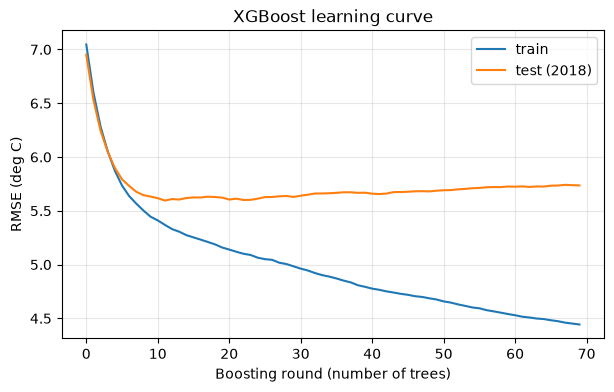

In [14]:
results = model.evals_result()
plt.figure(figsize=(7, 4))
plt.plot(results['validation_0']['rmse'], label='train')
plt.plot(results['validation_1']['rmse'], label='test (2018)')
plt.xlabel('Boosting round (number of trees)')
plt.ylabel('RMSE (deg C)')
plt.title('XGBoost learning curve')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**Question:** Compare the train and test curves. Does the training error keep decreasing? What about the test error?

> *The training error keeps decreasing.  The test error stops decreasing after number of trees equals 10 and starts to slightly increase*

# 6: Evaluate predictions, error, and metrics

### 6.1 Metrics

Three metrics are standard for regression models like this one:

- **RMSE** (root mean squared error): typical error size in the target's units (deg C). Penalizes large errors more heavily because errors are squared. This is the loss the model was trained on.
- **MAE** (mean absolute error): average absolute error in deg C. Less sensitive to outliers than RMSE. If RMSE is much larger than MAE, you have some big misses.
- **$R^2$** (coefficient of determination): the fraction of the variance in the target the model explains. 1 is perfect; 0 is no better than always predicting the mean of the data.

In [15]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

def report(y_true, y_pred, name):
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae  = mean_absolute_error(y_true, y_pred)
    r2   = r2_score(y_true, y_pred)
    print(f'{name:>5}:  RMSE = {rmse:.2f} C   MAE = {mae:.2f} C   R^2 = {r2:.3f}')

report(y_train, y_pred_train, 'train')
report(y_test,  y_pred_test,  'test')

# baseline: always predict the training-set mean temperature
baseline = np.full(len(y_test), y_train.mean())
report(y_test, baseline, 'base')

train:  RMSE = 4.44 C   MAE = 3.45 C   R^2 = 0.666
 test:  RMSE = 5.74 C   MAE = 4.54 C   R^2 = 0.423
 base:  RMSE = 7.55 C   MAE = 6.26 C   R^2 = -0.000


**Question:** How does the model's test performance compare to the baseline and to its own training performance? Is a test RMSE of this size acceptable for predicting temperature? (Compare it to the standard deviation of temperature you saw in the histogram.)

> *The model's performance is best on the train data by almost twice as much as the bae data.  The variation of temperature within a day might be twice as much as RSME so it gives a general prediction of what temperature will look like but not very precise.*

### 6.2 Predicted vs. observed

We'll first compute the residuals, defined as observed minus predicted (a positive residual means the model under-predicted). Then the most common diagnostic plot: predicted vs. observed. A perfect model puts every point on the 1:1 line.

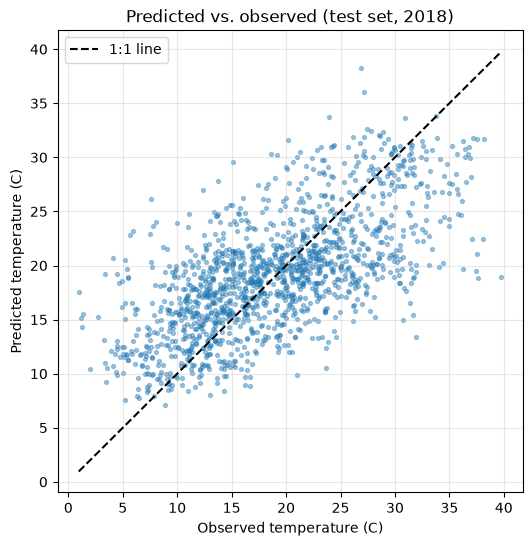

In [16]:
residuals = y_test - y_pred_test

plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred_test, s=8, alpha=0.4)
lims = [min(y_test.min(), y_pred_test.min()), max(y_test.max(), y_pred_test.max())]
plt.plot(lims, lims, 'k--', label='1:1 line')
plt.xlabel('Observed temperature (C)')
plt.ylabel('Predicted temperature (C)')
plt.title('Predicted vs. observed (test set, 2018)')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**Question:** How tightly do the points cluster around the 1:1 line? Where (cold or hot temperatures) does the model deviate the most, and in which direction?

> *The points cluster about 5 C off from the line and most of the deviation is at the higher temperatures and they deviate towards warmer values.*

### 6.3 Error distribution

A histogram of the residuals shows how large the errors typically are and whether the model is biased (errors centered away from zero).

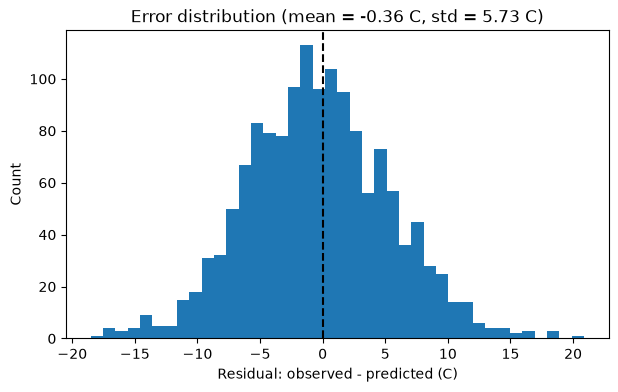

In [17]:
plt.figure(figsize=(7, 4))
plt.hist(residuals, bins=40)
plt.axvline(0, color='k', ls='--')
plt.xlabel('Residual: observed - predicted (C)')
plt.ylabel('Count')
plt.title(f'Error distribution (mean = {residuals.mean():.2f} C, std = {residuals.std():.2f} C)')
plt.show()

**Question:** Is the error distribution centered on zero? Is it symmetric? What would a mean residual far from zero tell you?

> *The mean residual does seem to center around 0.  The further from zero, the less accurate the model.*

### 6.4 Residuals vs. predicted

Plotting the residuals against the predicted values checks whether the errors depend on the prediction itself. In a well-behaved model the residuals scatter randomly around zero with no pattern.

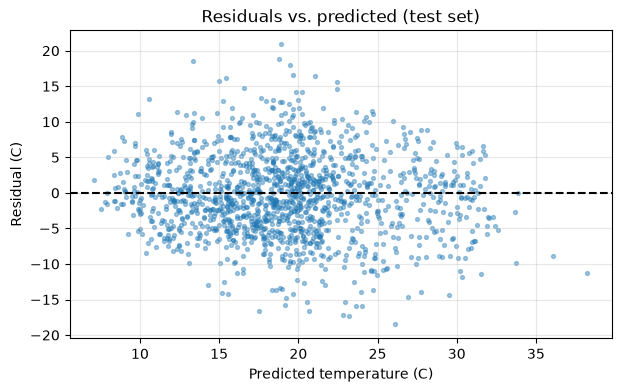

In [18]:
plt.figure(figsize=(7, 4))
plt.scatter(y_pred_test, residuals, s=8, alpha=0.4)
plt.axhline(0, color='k', ls='--')
plt.xlabel('Predicted temperature (C)')
plt.ylabel('Residual (C)')
plt.title('Residuals vs. predicted (test set)')
plt.grid(alpha=0.3)
plt.show()

**Question:** Do you see any structure (a trend, curve, or funnel shape) in the residuals? What would that structure imply about the model?

> *I don't see a structure in the residuals.  A structure like a funnel would indicate that there is a bias towards the side of the plot where the funnel is more narrow.  A curved shape would mean the relationship is nonlinear. *

### 6.5 Time series: observed vs. predicted

Finally, let's look at the predictions in time. Our test set was shuffled, so we first restore time order using the DataFrame index (which still holds the original row order). Because the data are only 5 sampled days per month, we use `.asfreq('h')` to insert gaps between sampled days so the plot doesn't draw misleading lines across them. We'll look at the first 5 sampled days of 2018.

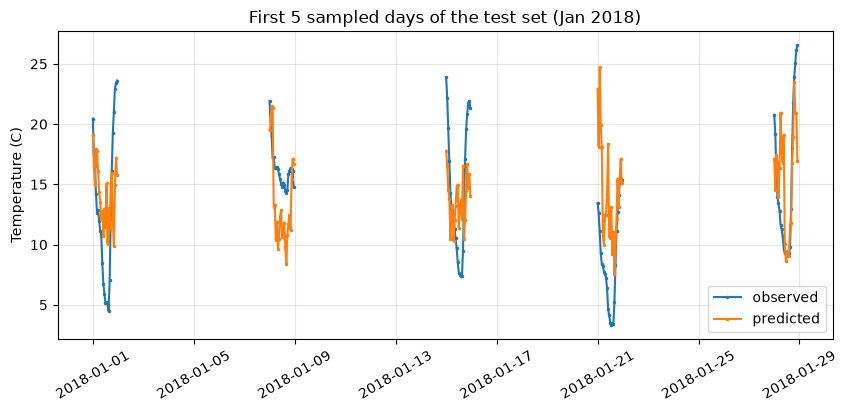

In [21]:
order = test.index.sort_values()          # original (time-ordered) row positions
obs_ts  = pd.Series(y_test.loc[order].values, index=df.loc[order, 'time'].values)
pred_ts = pd.Series(pd.Series(y_pred_test, index=y_test.index).loc[order].values, index=df.loc[order, 'time'].values)

plt.figure(figsize=(10, 4))
plt.plot(obs_ts.iloc[:119].asfreq('h'),  '.-', ms=3, label='observed')
plt.plot(pred_ts.iloc[:119].asfreq('h'), '.-', ms=3, label='predicted')
plt.ylabel('Temperature (C)')
plt.title('First 5 sampled days of the test set (Jan 2018)')
plt.xticks(rotation=30)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**Question:** Does the model reproduce the daily (day/night) temperature cycle? Why or why not, given the features we gave it?

> *The model reproduces the general trend of starting high and dipping and the final observations of the day going up, but does not align well for most of the days.  The observed data seems to be different enough even for days within the same month so we probably did not provide enough features of the day that would help provide more context for the predictions.*

# 7: Feature importance

XGBoost can tell us which covariates it relied on most. It has several definitions of "importance," selected with the `importance_type` argument of `xgb.plot_importance()`:

- **`weight`**: how many times a feature is used to split the data across all trees (a frequency count).
- **`gain`**: the average improvement in loss (reduction in error) when a split on that feature is made. This is usually the most meaningful measure.
- **`cover`**: the average number of training samples affected by splits on that feature.

We'll plot the **gain**-based importance.

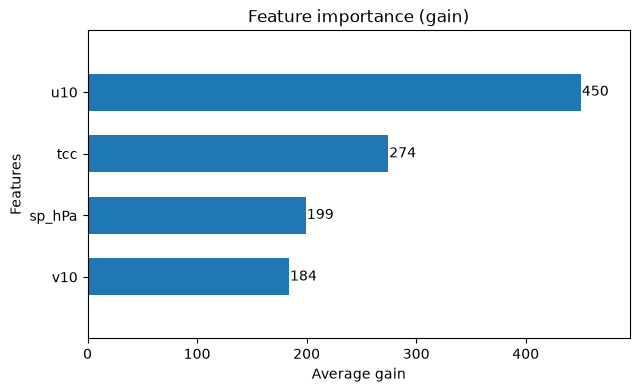

In [23]:
fig, ax = plt.subplots(figsize=(7, 4))
xgb.plot_importance(model, importance_type='gain', ax=ax, height=0.6,
                    title='Feature importance (gain)', xlabel='Average gain', show_values=True, values_format='{v:.0f}')
ax.grid(False)
plt.show()

**Question:** (a) Which feature does the model rely on most by `gain`? Does that agree with your physical intuition about what controls 2 m air temperature in LA? (b) Importance tells us what the model *used*, not what *causes* temperature. Name one limitation of interpreting these as physical drivers.

> *Model relies most on zonal component of wind speed at 10m height above surface.  This agrees partially with my physical intuition since at 2m movement of air helps move heat around, but in urban city like LA being at a park under a tree versus on an open concrete parking lot makes a big difference.  One limitation is the exclusion of albedo effect influenced by type of surface as well as comparison to other latitudes.*